In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')

c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready


In [2]:
from typing import TypedDict

class ReflectionState(TypedDict):
    task: str
    draft: str
    critique: str
    iteration: int

print('Reflection State is ready')

Reflection State is ready


In [3]:
# Generator node
def generate(state: ReflectionState):

    if state["draft"]:
        prompt = f"""
        You are an expert technical writer.

        Original task:
        {state["task"]}

        Previous draft:
        {state["draft"]}

        Critic feedback:
        {state["critique"]}

        Improve the previous draft based on the critic's feedback.

        Return only the improved draft.
        """
    else:
        prompt = f"""
        You are an expert technical writer.

        Write a high-quality answer for the following task:

        {state["task"]}

        Return only the draft.
        """

    response = model.invoke(prompt)

    return {
        "draft": response.content,
        "iteration": state["iteration"] + 1
    }

print('Generate node is ready')

Generate node is ready


In [4]:
# Reflection/Critic node
def reflect(state: ReflectionState):

    prompt = f"""
    You are a strict reviewer.

    Review the following answer against the original task.

    Original task:
    {state["task"]}

    Draft:
    {state["draft"]}

    Analyze:

    1. Accuracy
    2. Completeness
    3. Clarity
    4. Relevance
    5. Technical quality

    If the answer is good enough, start your response with:

    PASS

    Otherwise, start your response with:

    REVISE

    Then provide detailed feedback.
    """

    response = model.invoke(prompt)

    return {
        "critique": response.content
    }

print('Reflection node is ready')

Reflection node is ready


In [5]:
# Should continue node
def should_continue(state: ReflectionState):

    critique = state["critique"]

    if critique.strip().upper().startswith("PASS"):
        return "accept"

    if state["iteration"] >= 3:
        return "accept"

    return "improve"

print('should continue is ready')

should continue is ready


Graph is ready


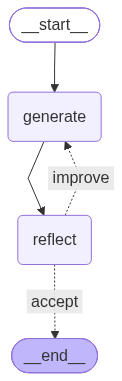

In [6]:
from langgraph.graph import StateGraph, START, END


builder = StateGraph(ReflectionState)

builder.add_node("generate", generate)
builder.add_node("reflect", reflect)

builder.add_edge(START, "generate")

builder.add_edge(
    "generate",
    "reflect"
)

builder.add_conditional_edges(
    "reflect",
    should_continue,
    {
        "improve": "generate",
        "accept": END
    }
)

graph = builder.compile()
print('Graph is ready')
graph

In [8]:
result = graph.invoke({
    "task": """
    Please suggest few tourist places in New Delhi for 2 days tour.
    """,
    "draft": "",
    "critique": "",
    "iteration": 0
})
result

{'task': '\n    Please suggest few tourist places in New Delhi for 2 days tour.\n    ',
 'draft': '**Draft – 2‑Day Tourist Itinerary for New\u202fDelhi**\n\n---\n\n## Overview\n- **Target audience:** First‑time visitors with limited time (≈\u202f48\u202fhours).  \n- **Objectives:** Showcase Delhi’s historic monuments, cultural hubs, and modern attractions while minimizing travel fatigue.  \n- **Assumptions:** Traveler will use a mix of metro, auto‑rickshaws, and short taxi rides; comfortable walking pace; interest in history, architecture, and local cuisine.\n\n---\n\n## Day\u202f1 – “The Imperial & Colonial Core”\n\n| Time (approx.) | Site | Highlights | Practical notes |\n|----------------|------|------------|-----------------|\n| 08:30\u202f–\u202f09:30 | **India Gate & Rajpath** | War memorial, wide boulevard, photo op with the backdrop of Rashtrapati Bhavan | Open 24\u202fh; best light early morning |\n| 09:45\u202f–\u202f11:30 | **Rashtrapati Bhavan (President’s House) – Outer vi